# MAIN_NoteBook: Predicting traffic impact at accident start

**Group members:** [ADD ALL GROUP MEMBERS]

## 1. Introduction

Can the context of a recorded accident help rank incidents assigned the upper
traffic-impact levels, and does this ranking remain useful in a later year?

Each observation represents a recorded accident. `Severity` is an ordered
traffic-impact label, not injury severity. Our binary target is **1 for levels
3 or 4, and 0 for levels 1 or 2**. This grouping is a study choice, with no
official threshold expressed in delay minutes.

We retain Source2, 33 admissible inputs, one histogram gradient boosting model,
and a constant baseline. The baseline assigns the training positive rate to
every incident. No logistic regression, Random Forest or pair search is trained
in this notebook.

**Historical reproduction:** the existing repository has already evaluated
2021 and 2022. We reuse its settings selected on 2020 and reproduce its results;
these years are not new, unseen tests. No settings are changed using their scores.

`Start_Time` is a retrospective prediction-time proxy. Actual publication times
and the time Severity was assigned are unknown. Deployment at first report is
not demonstrated.

Dataset: [US Accidents](https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents).
Target source recorded in the repository:
[creator metadata](https://www.kaggle.com/sobhanmoosavi/us-accidents/metadata).
See [target documentation](../docs/DOCUMENTATION_CIBLE.md).


### Related work and contribution

The repository's [literature summary](../docs/ETAT_DE_L_ART.md) describes
Moosavi et al., *A Countrywide Traffic Accident Dataset* (2019), which introduces
the dataset. Their *Accident Risk Prediction based on Heterogeneous Sparse Data*
(2019) concerns whether accidents occur, a different task from ranking the
impact of an already recorded accident. These notes are based on the local
summary, not a new review of the full papers.

Existing severity projects are listed in the repository. Their reported scores
cannot be compared directly without matching targets, permitted inputs, samples
and splits. Our contribution is a transparent temporal evaluation with
availability checks and an auditable preprocessing trail, not a new algorithm.


## 2. Preprocessing

### 2.1 Environment and paths

Open this notebook inside the repository and use a Python environment with
`requirements-main-notebook.txt` installed. The CSV is not distributed with
the notebook. Put it in `data/`, or set `CSV_PATH` below.

New caches, reports and figures are written under `data/main_notebook/`, which
is ignored by Git. Historical tables and the existing notebook are preserved.


In [12]:
from pathlib import Path
import hashlib
import json
import math
import time
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
while not (ROOT / "traffic_impact").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "traffic_impact").is_dir(), "Open the notebook inside the repository."
sys.path.insert(0, str(ROOT))
from traffic_impact import prepare
from traffic_impact.experiment import FeatureBuilder, raw_features, WNUM, WCAT, LIGHT, FORBIDDEN

candidates = [ROOT / "data/US_Accidents_March23.csv",
              ROOT.parent.parent / "US_Accidents_March23.csv"]
CSV_PATH = next((path for path in candidates if path.is_file()), candidates[0])
WORK = ROOT / "data/main_notebook"
REPORTS = WORK / "reports"
FIGURES = WORK / "figures"
for path in [REPORTS, FIGURES]:
    path.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110})
versions = {"python": sys.version.split()[0], "numpy": np.__version__,
            "pandas": pd.__version__, "sklearn": sklearn.__version__,
            "matplotlib": matplotlib.__version__}
display(pd.Series(versions, name="version").to_frame())


,version
python,3.10.11
numpy,2.2.6
pandas,2.3.3
sklearn,1.7.2
matplotlib,3.10.8


### 2.2 Full-file audit and reproducible event sampling

The repository's [preparation module](../traffic_impact/prepare.py) reads the
entire CSV in blocks of 250,000 rows. It records missingness, source/year/label
counts, repeated events, contradictory labels and weather timestamps.

Event identity uses Source, Start_Time, End_Time, start coordinates, Distance
and Description. These identity fields are not all predictors. Exact repeats
are collapsed; every event with conflicting Severity labels is excluded.
Nearby accidents are not automatically merged.

Uniform event priorities use seed 42 and do not depend on Severity. Sampling
is performed separately by time period, without class balancing. The module
first limits the distinct-event pools, then excludes conflicting events, so
final sizes may be slightly below the requested ceilings.

Cached samples are reused only when the CSV signature, preparation code hash,
sampling settings, Python/pandas/NumPy versions and sample file hashes match.
After an environment change, caches are rebuilt from the CSV automatically.
The first run audits the CSV.


In [13]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

assert CSV_PATH.is_file(), f"Download the CSV or update CSV_PATH: {CSV_PATH}"
limits = {"train": 200000, "validation": 50000, "test": 100000, "stress": 50000}
signature = {"csv": str(CSV_PATH.resolve()), "bytes": CSV_PATH.stat().st_size,
             "mtime_ns": CSV_PATH.stat().st_mtime_ns,
             "preparation_sha256": file_sha256(Path(prepare.__file__)),
             "cache_versions": {"python": list(sys.version_info[:2]),
                                "pandas": pd.__version__, "numpy": np.__version__},
             "limits": limits, "seed": 42}
stamp_path = WORK / "cache_manifest.json"
cache_paths = {split: WORK / "data/cache" / f"{split}.pkl" for split in limits}
saved_stamp = json.loads(stamp_path.read_text()) if stamp_path.exists() else {}
cache_valid = saved_stamp.get("signature") == signature
cache_valid = cache_valid and (WORK / "results/audit/audit.json").exists()
if cache_valid:
    cache_valid = all(path.exists() and file_sha256(path) ==
                      saved_stamp.get("sample_sha256", {}).get(split)
                      for split, path in cache_paths.items())
if not cache_valid:
    print("Rebuilding sample caches for the current data and environment.", flush=True)
    prepare.run(CSV_PATH, out=WORK, limits=limits)
    stamp_path.write_text(json.dumps({"signature": signature,
        "sample_sha256": {s: file_sha256(p) for s, p in cache_paths.items()}},
        indent=2), encoding="utf-8")
audit = json.loads((WORK / "results/audit/audit.json").read_text(encoding="utf-8"))
raw = {split: pd.read_pickle(path) for split, path in cache_paths.items()}
display(pd.DataFrame(audit["samples"]).T)
display(pd.Series({key: audit[key] for key in ["rows", "columns", "duplicate_ids",
    "source2_rows", "source2_duplicate_event_rows", "source2_conflicting_event_keys"]},
    name="full-file audit").to_frame())


,rows,high_impact_prevalence,first,last
train,199999,0.344067,2016-02-08 08:14:42,2019-12-31 23:50:02
validation,50000,0.30252,2020-01-01 00:23:14,2020-12-31 23:32:07
test,99999,0.342733,2021-01-01 00:13:44,2021-12-31 23:55:51
stress,50000,0.34696,2022-01-01 00:45:26,2022-09-08 17:41:15


,full-file audit
rows,7728394
columns,46
duplicate_ids,0
source2_rows,3305373
source2_duplicate_event_rows,2136
source2_conflicting_event_keys,8


### 2.3 Explore the original file and the selected samples

The first missingness table concerns all sources before cleaning. Class
proportions in sampled Source2 data have a different denominator. We show
both explicitly. Source2 reduces provider heterogeneity; it does not establish
better data quality or generalization to other providers.


,column,missing,missing_pct
8,End_Lng,3402762,44.029355
7,End_Lat,3402762,44.029355
27,Precipitation(in),2203586,28.512858
21,Wind_Chill(F),1999019,25.865904
26,Wind_Speed(mph),571233,7.391355
24,Visibility(mi),177098,2.291524
25,Wind_Direction,175206,2.267043
22,Humidity(%),174144,2.253301
28,Weather_Condition,173459,2.244438
20,Temperature(F),163853,2.120143


,Source,year,count,positive_count,positive_rate
0,Source1,2016,129560,36763,0.283753
1,Source1,2017,170702,55155,0.323107
2,Source1,2018,167761,56033,0.334005
3,Source1,2019,262369,55215,0.210448
4,Source1,2020,708669,72517,0.102328
5,Source1,2021,1113668,27223,0.024444
6,Source1,2022,1526270,41846,0.027417
7,Source1,2023,246633,7061,0.028630
8,Source2,2016,279666,103050,0.368475
9,Source2,2017,539528,196468,0.364148


,train,validation,test,stress
Severity,,,,
1,74,14,31,7694
2,131112,34860,65695,24958
3,68398,14635,33452,17028
4,415,491,821,320


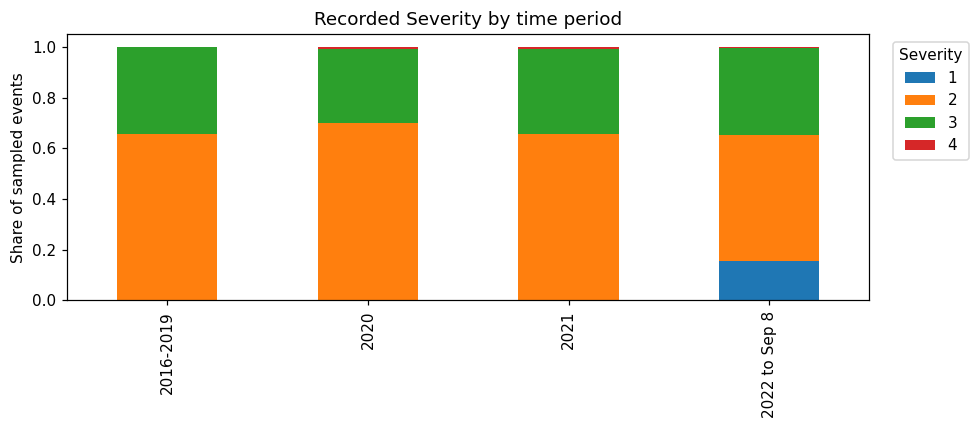

In [14]:
original_missing = pd.read_csv(WORK / "results/audit/columns.csv")
display(original_missing.sort_values("missing_pct", ascending=False).head(12))
yearly = pd.read_csv(WORK / "results/audit/monthly_source_severity.csv")
yearly["year"] = yearly["_month"].str[:4]
yearly["positive_count"] = yearly["count"].where(yearly.Severity.ge(3), 0)
source_year = yearly.groupby(["Source", "year"])[["count", "positive_count"]].sum()
source_year["positive_rate"] = source_year.positive_count / source_year["count"]
display(source_year.reset_index())
class_counts = pd.DataFrame({s: d.Severity.value_counts().sort_index() for s, d in raw.items()}).fillna(0)
display(class_counts.astype(int))
period_labels = {"train": "2016-2019", "validation": "2020", "test": "2021", "stress": "2022 to Sep 8"}
ax = class_counts.T.div(class_counts.sum(), axis=0).rename(index=period_labels).plot.bar(stacked=True)
ax.set(ylabel="Share of sampled events", title="Recorded Severity by time period")
ax.legend(title="Severity", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(FIGURES / "01_class_distribution.png")
plt.show()


### 2.4 Essential validity checks

Records without a valid start date or a label in 1, 2, 3, 4 cannot be used.
Remove them and report the number removed, without imputing the target.
For predictors, flag impossible values using physical bounds, not statistical
rarity. Invalid numeric values become missing; plausible extremes remain.
The next checks apply to the sampled events, not every unsampled predictor.

Negative duration is audited at full-file level but is not a predictor.


In [15]:
quality_rows, invalid_rows = [], []
cleaned_raw = {}
bounds = {"Start_Lat": (-90, 90), "Start_Lng": (-180, 180),
          "Humidity(%)": (0, 100), "Precipitation(in)": (0, np.inf),
          "Wind_Speed(mph)": (0, np.inf), "Visibility(mi)": (0, np.inf),
          "Pressure(in)": (0, np.inf)}
invalid_maps = []
for split, frame in raw.items():
    frame = frame.copy()
    frame["_t"] = pd.to_datetime(frame.Start_Time, format="mixed", errors="coerce")
    valid = frame["_t"].notna() & frame.Severity.isin([1, 2, 3, 4])
    quality_rows.append({"split": split, "before": len(frame),
                         "invalid_date_or_label": int((~valid).sum()), "after": int(valid.sum())})
    frame = frame.loc[valid].reset_index(drop=True)
    for column, (lower, upper) in bounds.items():
        before = frame[column].copy()
        numeric = pd.to_numeric(before, errors="coerce")
        invalid = numeric.notna() & (~numeric.between(lower, upper) | ~np.isfinite(numeric))
        invalid_rows.append({"split": split, "column": column, "invalid_values": int(invalid.sum())})
        if invalid.any():
            counts = before[invalid].astype(str).value_counts()
            invalid_maps.extend({"split": split, "column": column, "before": value,
                                 "after": "<MISSING>", "count": int(count)}
                                for value, count in counts.items())
        frame[column] = numeric.mask(invalid)
    cleaned_raw[split] = frame
quality = pd.DataFrame(quality_rows)
invalid_values = pd.DataFrame(invalid_rows)
quality.to_csv(REPORTS / "record_cleaning.csv", index=False)
invalid_values.to_csv(REPORTS / "invalid_numeric_values.csv", index=False)
pd.DataFrame(invalid_maps, columns=["split", "column", "before", "after", "count"]).to_csv(
    REPORTS / "invalid_numeric_mappings.csv", index=False)
display(quality)
display(invalid_values.groupby("column").invalid_values.sum().to_frame())
print("Negative durations in the full CSV:", audit["negative_durations"])


,split,before,invalid_date_or_label,after
0,train,199999,0,199999
1,validation,50000,0,50000
2,test,99999,0,99999
3,stress,50000,0,50000


,invalid_values
column,
Humidity(%),0
Precipitation(in),0
Pressure(in),0
Start_Lat,0
Start_Lng,0
Visibility(mi),0
Wind_Speed(mph),0


Negative durations in the full CSV: 0


### 2.5 Temporal split and target

Train: 2016-2019. Validation: 2020. Historical test: 2021. Stability check:
available Source2 observations in 2022, ending September 8. There is no
random split across years and no synthetic class balancing.

Feature transformations and vocabularies will be learned on training data only.
The binary target is kept separately from model inputs.


In [16]:
expected_years = {"train": {2016, 2017, 2018, 2019}, "validation": {2020},
                  "test": {2021}, "stress": {2022}}
y, ties = {}, {}
for split, frame in cleaned_raw.items():
    assert frame.Source.eq("Source2").all()
    assert set(frame["_t"].dt.year.unique()) <= expected_years[split]
    assert frame["_event"].is_unique
    y[split] = frame.Severity.ge(3).astype("int8").to_numpy()
    ties[split] = frame["_priority"].to_numpy()
for first, second in [("train", "validation"), ("train", "test"),
                      ("train", "stress"), ("validation", "test"),
                      ("validation", "stress"), ("test", "stress")]:
    assert cleaned_raw[first]["_t"].max() < cleaned_raw[second]["_t"].min()
    assert not set(cleaned_raw[first]["_event"]) & set(cleaned_raw[second]["_event"])
display(pd.DataFrame({s: {"events": len(v), "positive_rate": float(v.mean())}
                      for s, v in y.items()}).T)


,events,positive_rate
train,199999.0,0.344067
validation,50000.0,0.302520
test,99999.0,0.342733
stress,50000.0,0.346960


### 2.6 Build admissible inputs and audit weather availability

[raw_features](../traffic_impact/experiment.py) derives hour, day_of_week,
month and weekend. It keeps start geography, road indicators and light fields.
ID, Source, Severity, end coordinates, end time, distance, description, fine
addresses and station identifiers are excluded from predictors.

Weather must have an observation timestamp in [start minus 120 minutes, start].
If missing, too old or future-dated, all nine weather fields are masked while
the accident stays in the data. Timestamp eligibility does not establish
publication-time availability. Wind direction spelling is harmonized without
merging NE and NW. This cell creates the pre-vocabulary feature tables.


In [17]:
before_categories, feature_groups, eligible = {}, {}, {}
weather_rows = []
for split, frame in cleaned_raw.items():
    features, groups, valid_weather = raw_features(frame)
    before_categories[split] = features
    feature_groups = groups
    eligible[split] = valid_weather
    weather_time = pd.to_datetime(frame.Weather_Timestamp, format="mixed", errors="coerce")
    lag = (frame["_t"] - weather_time).dt.total_seconds() / 60
    weather_rows.append({"split": split, "events": len(frame),
        "eligible_weather": int(valid_weather.sum()),
        "future_observation": int(lag.lt(0).sum()),
        "older_than_120_minutes": int(lag.gt(120).sum()),
        "missing_or_invalid_timestamp": int(lag.isna().sum())})
    assert features.loc[~valid_weather, WNUM + WCAT].isna().all().all()
weather_audit = pd.DataFrame(weather_rows)
weather_audit.to_csv(REPORTS / "weather_availability.csv", index=False)
display(weather_audit)


,split,events,eligible_weather,future_observation,older_than_120_minutes,missing_or_invalid_timestamp
0,train,199999,98638,98542,588,2231
1,validation,50000,25195,24022,108,675
2,test,99999,49941,48641,236,1181
3,stress,50000,25092,24169,152,587


### 2.7 Learn constants and category vocabularies on training only

Fit the repository's FeatureBuilder on training events. A categorical value
needs at least 100 training occurrences to be retained; Weather_Condition keeps
at most the 15 most frequent eligible categories. Other observed values and
future unseen values become Other. Missing values become Missing.

These are fixed historical choices, not proven optimal settings. All observed
training categories are also saved, so rare known categories can be distinguished
from categories never observed during training. Constant candidates such as
Turning_Loop are removed using training data only.

The resulting classifier handles numeric missingness and categories natively.
There is no median imputation, one-hot encoding or standardization for this model.


In [18]:
builder = FeatureBuilder().fit(cleaned_raw["train"])
X = {split: builder.transform(frame) for split, frame in cleaned_raw.items()}
seen_in_train = {column: set(before_categories["train"][column].dropna().astype(str))
                 for column in builder.vocab}
feature_dictionary = pd.DataFrame({"feature": builder.columns,
    "group": [builder.groups[c] for c in builder.columns],
    "dtype": [str(X["train"][c].dtype) for c in builder.columns]})
display(feature_dictionary)
print("Removed training constants:", builder.dropped)
assert len(builder.columns) == 33
assert not set(builder.columns) & FORBIDDEN
for split, features in X.items():
    assert list(features.columns) == builder.columns
    assert features.index.equals(cleaned_raw[split].index)
feature_dictionary.to_csv(REPORTS / "feature_dictionary.csv", index=False)
vocabulary = {"retained": builder.vocab,
              "all_training_categories": {c: sorted(v) for c, v in seen_in_train.items()},
              "removed_constants": builder.dropped}
(REPORTS / "training_vocabulary.json").write_text(json.dumps(vocabulary, indent=2), encoding="utf-8")


,feature,group,dtype
0,hour,time,int32
1,day_of_week,time,int32
2,month,time,int32
3,weekend,time,int64
4,Start_Lat,geography,float64
5,Start_Lng,geography,float64
6,State,geography,category
7,Timezone,geography,category
8,Amenity,road,float64
9,Bump,road,float64


Removed training constants: ['Turning_Loop']


4623

### 2.8 Complete before/after transformation ledger

Every harmonization rule gets a count, a percentage of events and before/after
category counts, even if it changes zero cells. Exact value transitions and
category frequencies are exported in full to CSV; notebook displays are compact.

The ledger separates whitespace removal, wind casing, wind aliases, numeric
parsing, weather masking, missing-category assignment and Other grouping.
The same event may be affected by multiple steps. A separate union counts
each affected event once. The total step changes is not a unique-cell count.
Dtype changes are reported separately from value changes.


In [19]:
change_rows, mapping_rows, frequency_rows, global_rows = [], [], [], []

def audit_transition(split, column, rule, before, after, affected):
    left = before.astype("string").fillna("<MISSING>")
    right = after.astype("string").fillna("<MISSING>")
    changed = left.ne(right).to_numpy()
    affected |= changed
    change_rows.append({"split": split, "column": column, "rule": rule,
        "events": len(before), "changed_cells": int(changed.sum()),
        "changed_pct": float(100 * changed.mean()),
        "categories_before": int(left.nunique()), "categories_after": int(right.nunique()),
        "dtype_before": str(before.dtype), "dtype_after": str(after.dtype)})
    transitions = pd.DataFrame({"before": left[changed], "after": right[changed]})
    for (old, new), count in transitions.value_counts(sort=False).items():
        mapping_rows.append({"split": split, "column": column, "rule": rule,
                             "before": old, "after": new, "count": int(count)})
    for stage, series in [("before", left), ("after", right)]:
        for value, count in series.value_counts().items():
            frequency_rows.append({"split": split, "column": column, "rule": rule,
                "stage": stage, "value": value, "count": int(count),
                "frequency": float(count / len(series))})

aliases = {"NORTH": "N", "SOUTH": "S", "EAST": "E", "WEST": "W",
           "CALM": "Calm", "VAR": "Variable", "VARIABLE": "Variable"}
for split, frame in cleaned_raw.items():
    affected = np.zeros(len(frame), dtype=bool)
    direction = frame.Wind_Direction.astype("string")
    for rule, operation in [("strip whitespace", lambda z: z.str.strip()),
                            ("uppercase direction", lambda z: z.str.upper()),
                            ("normalize direction aliases", lambda z: z.replace(aliases))]:
        updated = operation(direction)
        audit_transition(split, "Wind_Direction", rule, direction, updated, affected)
        direction = updated
    for column in WNUM + WCAT:
        original = direction if column == "Wind_Direction" else frame[column]
        if column in WNUM:
            parsed = pd.to_numeric(original, errors="coerce")
            audit_transition(split, column, "parse numeric weather", original, parsed, affected)
            original = parsed
        masked = original.where(eligible[split])
        audit_transition(split, column, "weather timestamp gate", original, masked, affected)
    for column in builder.vocab:
        original = before_categories[split][column].astype("string")
        missing_named = original.fillna("Missing")
        audit_transition(split, column, "assign Missing", original, missing_named, affected)
        final = X[split][column].astype("string")
        audit_transition(split, column, "group rare or unseen as Other", missing_named, final, affected)
    global_rows.append({"split": split, "events": len(frame),
        "affected_events_once": int(affected.sum()), "affected_events_pct": float(100 * affected.mean())})

changes = pd.DataFrame(change_rows)
mappings = pd.DataFrame(mapping_rows, columns=["split", "column", "rule", "before", "after", "count"])
frequencies = pd.DataFrame(frequency_rows)
global_changes = pd.DataFrame(global_rows)
global_changes["sum_of_step_changes"] = global_changes.split.map(changes.groupby("split").changed_cells.sum())
for name, table in [("transformation_summary", changes), ("before_after_mappings", mappings),
                    ("category_frequencies", frequencies), ("affected_event_summary", global_changes)]:
    table.to_csv(REPORTS / f"{name}.csv", index=False)
display(changes.groupby(["rule", "column"]).changed_cells.sum().to_frame())
display(mappings.sort_values("count", ascending=False).head(20))
display(global_changes)


changed_cells
rule                          column                              
assign Missing                Astronomical_Twilight            334
                              Civil_Twilight                   334
                              Nautical_Twilight                334
                              State                              0
                              Sunrise_Sunset                   334
                              Timezone                         331
                              Weather_Condition             202345
                              Wind_Direction                202060
group rare or unseen as Other Astronomical_Twilight              0
                              Civil_Twilight                     0
                              Nautical_Twilight                  0
                              State                            521
                              Sunrise_Sunset                     0
                              Timezone                           0
                              Weather_Condition               6087
                              Wind_Direction                     0
normalize direction aliases   Wind_Direction                129984
parse numeric weather         Humidity(%)                        0
                              Precipitation(in)                  0
                              Pressure(in)                       0
                              Temperature(F)                     0
                              Visibility(mi)                     0
                              Wind_Chill(F)                      0
                              Wind_Speed(mph)                    0
strip whitespace              Wind_Direction                     0
uppercase direction           Wind_Direction                 74960
weather timestamp gate        Humidity(%)                   195168
                              Precipitation(in)             126336
                              Pressure(in)                  195917
                              Temperature(F)                195411
                              Visibility(mi)                195063
                              Weather_Condition             195109
                              Wind_Chill(F)                 132450
                              Wind_Direction                195517
                              Wind_Speed(mph)               181818

,split,column,rule,before,after,count
2507,train,Weather_Condition,assign Missing,<MISSING>,Missing,102176
2506,train,Wind_Direction,assign Missing,<MISSING>,Missing,101552
2194,train,Visibility(mi),weather timestamp gate,10.0,<MISSING>,78810
5224,test,Wind_Direction,assign Missing,<MISSING>,Missing,50378
5225,test,Weather_Condition,assign Missing,<MISSING>,Missing,50256
5038,test,Precipitation(in),weather timestamp gate,0.0,<MISSING>,44189
4983,test,Visibility(mi),weather timestamp gate,10.0,<MISSING>,38694
6,train,Wind_Direction,normalize direction aliases,CALM,Calm,33973
2425,train,Weather_Condition,weather timestamp gate,Clear,<MISSING>,28287
0,train,Wind_Direction,uppercase direction,Calm,CALM,25905


,split,events,affected_events_once,affected_events_pct,sum_of_step_changes
0,train,199999,145829,72.914865,1110368
1,validation,50000,31481,62.962000,277179
2,test,99999,64139,64.139641,562431
3,stress,50000,31921,63.842000,280435


### 2.9 Missingness before and after preparation

After preparation, Missing is an explicit categorical absence; numeric NaN
stays missing. Weather masking can increase missingness. It does not remove
accidents. Compare the same feature names and the same events on both sides.


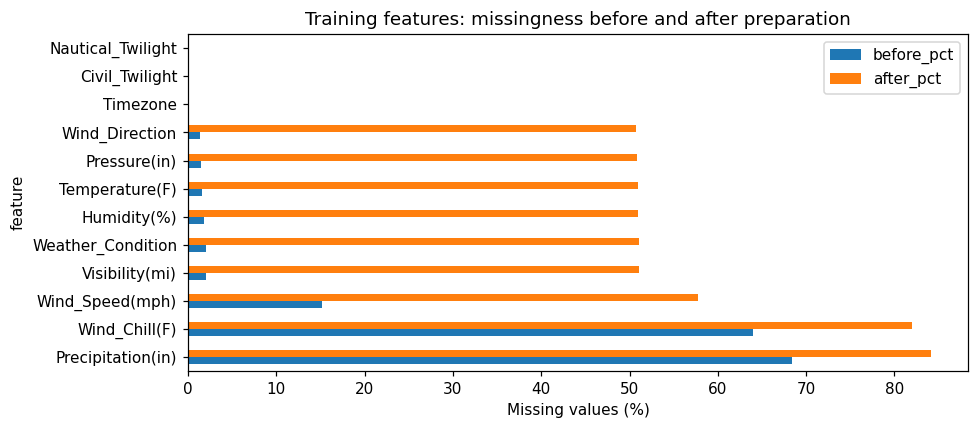

In [20]:
missing_rows = []
for split, frame in cleaned_raw.items():
    for column in builder.columns:
        if column in frame:
            initial = frame[column].isna().mean()
        else:
            initial = before_categories[split][column].isna().mean()
        final = X[split][column]
        final_missing = final.eq("Missing") if column in builder.vocab else final.isna()
        missing_rows.append({"split": split, "feature": column,
                             "before_pct": 100 * float(initial),
                             "after_pct": 100 * float(final_missing.mean())})
missingness = pd.DataFrame(missing_rows)
missingness.to_csv(REPORTS / "missingness_before_after.csv", index=False)
train_missing = missingness[missingness.split.eq("train")].set_index("feature")
plot_missing = train_missing.loc[train_missing.after_pct.sort_values(ascending=False).head(12).index]
plot_missing[["before_pct", "after_pct"]].plot.barh()
plt.xlabel("Missing values (%)")
plt.title("Training features: missingness before and after preparation")
plt.tight_layout()
plt.savefig(FIGURES / "02_missingness.png")
plt.show()


### 2.10 Weather category drift, without changing the vocabulary

For each year and weather categorical field, distinguish retained values,
values observed in training but grouped, unseen values and missing values.
Rates use all events; an additional denominator uses non-missing eligible
observations. The training seen-set is frozen across all years.

Category-level counts and positive rates are descriptive. Future category
statistics never update the vocabulary. A larger Other rate is not proof of
a causal explanation for a performance change. Alternative category caps are
outside this minimal notebook and remain a possible follow-up.


In [21]:
def category_status(series, column):
    values = series.astype("string")
    status = pd.Series("unseen", index=series.index)
    status.loc[values.isin(seen_in_train[column])] = "known_grouped"
    status.loc[values.isin(builder.vocab[column])] = "retained"
    status.loc[values.isna()] = "missing"
    return status

drift_parts, category_parts = [], []
for split, frame in cleaned_raw.items():
    for column in WCAT:
        values = before_categories[split][column]
        detail = pd.DataFrame({"year": frame["_t"].dt.year, "status": category_status(values, column),
                               "category": values.astype("string").fillna("<MISSING>"), "target": y[split]})
        grouped = detail.groupby(["year", "status"]).agg(events=("target", "size"), positives=("target", "sum")).reset_index()
        annual_total = detail.groupby("year").size()
        annual_nonmissing = detail[detail.status.ne("missing")].groupby("year").size()
        grouped["rate_all_events"] = grouped.events / grouped.year.map(annual_total)
        grouped["rate_nonmissing"] = grouped.events / grouped.year.map(annual_nonmissing)
        grouped.loc[grouped.status.eq("missing"), "rate_nonmissing"] = np.nan
        grouped["positive_rate"] = grouped.positives / grouped.events
        grouped["column"], grouped["split"] = column, split
        drift_parts.append(grouped)
        by_category = detail.groupby(["year", "status", "category"]).agg(
            events=("target", "size"), positives=("target", "sum")).reset_index()
        by_category["frequency"] = by_category.events / by_category.year.map(annual_total)
        by_category["positive_rate"] = by_category.positives / by_category.events
        by_category["annual_positive_rate"] = by_category.year.map(detail.groupby("year").target.mean())
        by_category["train_count"] = by_category.category.map(
            before_categories["train"][column].astype("string").fillna("<MISSING>").value_counts()).fillna(0).astype(int)
        by_category["train_positive_rate"] = by_category.category.map(pd.DataFrame({
            "category": before_categories["train"][column].astype("string").fillna("<MISSING>"),
            "target": y["train"]}).groupby("category").target.mean())
        by_category["column"], by_category["split"] = column, split
        category_parts.append(by_category)
drift = pd.concat(drift_parts, ignore_index=True)
category_detail = pd.concat(category_parts, ignore_index=True)
drift.to_csv(REPORTS / "weather_category_drift.csv", index=False)
category_detail.to_csv(REPORTS / "weather_category_details.csv", index=False)
display(drift[drift.column.eq("Weather_Condition")].round(4))
display(category_detail[category_detail.status.isin(["unseen", "known_grouped"])].sort_values("events", ascending=False).head(15))


,year,status,events,positives,rate_all_events,rate_nonmissing,positive_rate,column,split
8,2016,known_grouped,104,47,0.0041,0.0085,0.4519,Weather_Condition,train
9,2016,missing,12882,4778,0.5127,NaN,0.3709,Weather_Condition,train
10,2016,retained,12142,4448,0.4832,0.9915,0.3663,Weather_Condition,train
11,2017,known_grouped,294,121,0.0060,0.0123,0.4116,Weather_Condition,train
12,2017,missing,24930,9125,0.5111,NaN,0.3660,Weather_Condition,train
13,2017,retained,23556,8563,0.4829,0.9877,0.3635,Weather_Condition,train
14,2018,known_grouped,496,218,0.0077,0.0156,0.4395,Weather_Condition,train
15,2018,missing,33060,11896,0.5105,NaN,0.3598,Weather_Condition,train
16,2018,retained,31199,11056,0.4818,0.9844,0.3544,Weather_Condition,train
17,2019,known_grouped,1007,371,0.0164,0.0335,0.3684,Weather_Condition,train


,year,status,category,events,positives,frequency,positive_rate,annual_positive_rate,train_count,train_positive_rate,column,split
356,2021,known_grouped,Fair / Windy,327,138,0.003270,0.422018,0.342733,115,0.286957,Weather_Condition,test
387,2021,known_grouped,T-Storm,170,88,0.001700,0.517647,0.342733,94,0.414894,Weather_Condition,test
391,2021,known_grouped,Thunder in the Vicinity,151,62,0.001510,0.410596,0.342733,76,0.328947,Weather_Condition,test
437,2022,known_grouped,Fair / Windy,145,60,0.002900,0.413793,0.346960,115,0.286957,Weather_Condition,stress
371,2021,known_grouped,Light Rain with Thunder,134,72,0.001340,0.537313,0.342733,68,0.455882,Weather_Condition,test
389,2021,known_grouped,Thunder,131,59,0.001310,0.450382,0.342733,71,0.352113,Weather_Condition,test
307,2020,known_grouped,Smoke,130,32,0.002600,0.246154,0.302520,102,0.372549,Weather_Condition,validation
353,2021,known_grouped,Cloudy / Windy,122,53,0.001220,0.434426,0.342733,65,0.446154,Weather_Condition,test
374,2021,known_grouped,Mostly Cloudy / Windy,120,46,0.001200,0.383333,0.342733,67,0.283582,Weather_Condition,test
285,2020,known_grouped,Fair / Windy,117,42,0.002340,0.358974,0.302520,115,0.286957,Weather_Condition,validation


## 3. Training

A histogram gradient boosting classifier builds trees sequentially. Each new
tree corrects the current ensemble using the loss gradient. Numerical values
are binned to accelerate split search. Trees can learn interactions such as
location-dependent associations with time or road indicators.

Reuse the historical validation-selected settings: **200 iterations, at most
31 leaves per tree, learning rate 0.1**. No random early-stopping split and no
class weights are used. Seed 42 and four computation threads make the run
reproducible and limit resource use. We do not rerun a hyperparameter search.

The constant baseline is the training positive rate. Both methods are learned
from training data only. The following cell actually fits the main model.


In [22]:
frozen = json.loads((ROOT / "results/frozen_selection.json").read_text(encoding="utf-8"))
assert frozen["hgb_parameters"] == {"max_leaf_nodes": 31, "max_iter": 200}
assert frozen["test_used_for_selection"] is False
assert builder.columns == frozen["models"]["hgb_full"]["columns"]
settings = {"max_iter": 200, "max_leaf_nodes": 31, "learning_rate": 0.1,
            "categorical_features": "from_dtype", "early_stopping": False, "random_state": 42}
prior = float(y["train"].mean())
started = time.perf_counter()
main_model = HistGradientBoostingClassifier(**settings)
with threadpool_limits(limits=4):
    main_model.fit(X["train"], y["train"])
training_seconds = time.perf_counter() - started
print(f"Training events: {len(y['train']):,}; inputs: {len(builder.columns)}")
print(f"Baseline score: {prior:.6f}; main-model training: {training_seconds:.2f} seconds")
print("Settings:", settings)


Training events: 199,999; inputs: 33
Baseline score: 0.344067; main-model training: 5.53 seconds
Settings: {'max_iter': 200, 'max_leaf_nodes': 31, 'learning_rate': 0.1, 'categorical_features': 'from_dtype', 'early_stopping': False, 'random_state': 42}


## 4. Evaluation

**Average Precision (AP)** summarizes precision along the recall curve; the
constant baseline AP equals the evaluated period's positive prevalence.
**ROC-AUC** measures positive-versus-negative ranking and is 0.5 for constant
scores when both classes exist. Neither metric is classification accuracy.

**Top-10% precision:** the positive fraction among the highest-ranked 10%.
**Top-10% recall:** the fraction of all positives found in that budget.
The number selected is ceil(0.10 times the sample size). Ties are resolved
using saved event priorities independent of the target. Baseline recall is
approximately, not necessarily exactly, 10% because this is a finite sample.

No threshold of 0.5 is imposed on the primary ranking evaluation. The top-10%
budget is a retrospective ranking policy, not a validated streaming alert service.
Section 4.1 separately assesses raw scores and two post-hoc calibration methods,
then chooses illustrative thresholds on a held-out part of 2020. Calibration and
threshold results remain historical analyses, not deployment validation.

In [23]:
def evaluate(target, prediction, priority):
    target = np.asarray(target)
    prediction = np.asarray(prediction, dtype=float)
    assert len(target) == len(prediction) == len(priority)
    assert len(target) > 0 and np.isin(target, [0, 1]).all()
    assert np.isfinite(prediction).all() and ((prediction >= 0) & (prediction <= 1)).all()
    selected_count = max(1, math.ceil(0.10 * len(target)))
    selected = np.lexsort((priority, -prediction))[:selected_count]
    positives = int(target.sum())
    return {"n": len(target), "prevalence": float(target.mean()),
            "ap": float(average_precision_score(target, prediction)) if positives else np.nan,
            "auc": float(roc_auc_score(target, prediction)) if 0 < positives < len(target) else np.nan,
            "recall10": float(target[selected].sum() / positives) if positives else np.nan,
            "precision10": float(target[selected].mean()), "selected_count": selected_count}

predictions, score_rows = {}, []
with threadpool_limits(limits=4):
    for split in ["validation", "test", "stress"]:
        predictions[split] = {"prior": np.full(len(y[split]), prior),
                              "hgb_full": main_model.predict_proba(X[split])[:, 1]}
        for name, prediction in predictions[split].items():
            score_rows.append({"split": split, "name": name, **evaluate(y[split], prediction, ties[split])})
scores = pd.DataFrame(score_rows)
scores.to_csv(REPORTS / "main_scores.csv", index=False)
display(scores.round(6))


,split,name,n,prevalence,ap,auc,recall10,precision10,selected_count
0,validation,prior,50000,0.302520,0.302520,0.500000,0.102076,0.3088,5000
1,validation,hgb_full,50000,0.302520,0.696948,0.849606,0.263983,0.7986,5000
2,test,prior,99999,0.342733,0.342733,0.500000,0.097745,0.3350,10000
3,test,hgb_full,99999,0.342733,0.703118,0.836234,0.233799,0.8013,10000
4,stress,prior,50000,0.346960,0.346960,0.500000,0.101856,0.3534,5000
5,stress,hgb_full,50000,0.346960,0.709157,0.835069,0.233456,0.8100,5000


### 4.1 Probability calibration and operating thresholds

Ranking metrics do not determine a useful alert threshold. This analysis compares the raw HGB scores with Platt (sigmoid) and isotonic calibration. The calibrators are fit only on January-June 2020. Thresholds are selected only on July-December 2020, then applied unchanged to the historical 2021 test. The 2021 results are a historical evaluation, not a new independent test, because this period has already been examined in the project.

Reliability curves on the second half of 2020 and 2021 compare predicted probabilities with observed positive rates. The threshold table reports precision, recall, F1, alert volume and false alarms. There is no universally best threshold without an operational alert capacity or a relative cost for missed events versus false alarms. The F1-selected threshold is shown as one reference policy, not as a deployment recommendation.

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss

validation_dates = cleaned_raw["validation"]["_t"]
calibration_mask = (validation_dates < "2020-07-01").to_numpy()
threshold_mask = ~calibration_mask
validation_target = y["validation"]
test_target = y["test"]
validation_raw = predictions["validation"]["hgb_full"]
test_raw = predictions["test"]["hgb_full"]

assert calibration_mask.any() and threshold_mask.any()
assert len(np.unique(validation_target[calibration_mask])) == 2


def score_logit(probability):
    clipped = np.clip(np.asarray(probability, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(clipped / (1 - clipped)).reshape(-1, 1)


platt_calibrator = LogisticRegression(C=1.0, solver="lbfgs", random_state=42)
platt_calibrator.fit(score_logit(validation_raw[calibration_mask]),
                     validation_target[calibration_mask])
isotonic_calibrator = IsotonicRegression(out_of_bounds="clip")
isotonic_calibrator.fit(validation_raw[calibration_mask],
                        validation_target[calibration_mask])

calibrated_probabilities = {
    "Raw": {
        "validation": validation_raw,
        "test": test_raw,
    },
    "Platt": {
        "validation": platt_calibrator.predict_proba(score_logit(validation_raw))[:, 1],
        "test": platt_calibrator.predict_proba(score_logit(test_raw))[:, 1],
    },
    "Isotonic": {
        "validation": isotonic_calibrator.predict(validation_raw),
        "test": isotonic_calibrator.predict(test_raw),
    },
}


def threshold_metrics(target, probability, threshold):
    target = np.asarray(target, dtype=int)
    alert = np.asarray(probability) >= threshold
    tp = int(np.sum(alert & (target == 1)))
    fp = int(np.sum(alert & (target == 0)))
    fn = int(np.sum(~alert & (target == 1)))
    tn = int(np.sum(~alert & (target == 0)))
    alert_count = tp + fp
    precision_value = tp / alert_count if alert_count else 0.0
    recall_value = tp / (tp + fn) if tp + fn else np.nan
    f1_denominator = 2 * tp + fp + fn
    return {
        "threshold": float(threshold),
        "events": len(target),
        "alert_count": alert_count,
        "alert_rate": alert.mean(),
        "true_positives": tp,
        "false_alarms": fp,
        "false_alarms_per_1000": 1000 * fp / len(target),
        "missed_positives": fn,
        "precision": precision_value,
        "recall": recall_value,
        "f1": 2 * tp / f1_denominator if f1_denominator else 0.0,
        "specificity": tn / (tn + fp) if tn + fp else np.nan,
    }


probability_metrics = []
for method, split_probabilities in calibrated_probabilities.items():
    for split, target in [("validation_holdout", validation_target[threshold_mask]),
                          ("test_2021", test_target)]:
        probability = (split_probabilities["validation"][threshold_mask]
                      if split == "validation_holdout" else split_probabilities["test"])
        clipped = np.clip(probability, 1e-15, 1 - 1e-15)
        probability_metrics.append({
            "method": method,
            "split": split,
            "events": len(target),
            "prevalence": float(np.mean(target)),
            "average_precision": average_precision_score(target, probability),
            "roc_auc": roc_auc_score(target, probability),
            "brier": brier_score_loss(target, probability),
            "log_loss": log_loss(target, clipped, labels=[0, 1]),
        })
calibration_summary = pd.DataFrame(probability_metrics)
calibration_summary.to_csv(REPORTS / "calibration_summary.csv", index=False)
display(calibration_summary.round(4))

thresholds = np.round(np.arange(0.05, 0.951, 0.05), 2)
threshold_rows = []
for method, split_probabilities in calibrated_probabilities.items():
    for split, target, probability in [
        ("validation_holdout", validation_target[threshold_mask],
         split_probabilities["validation"][threshold_mask]),
        ("test_2021", test_target, split_probabilities["test"]),
    ]:
        for threshold in thresholds:
            threshold_rows.append({"method": method, "split": split,
                                   **threshold_metrics(target, probability, threshold)})
threshold_sweep = pd.DataFrame(threshold_rows)
threshold_sweep.to_csv(REPORTS / "calibration_threshold_sweep.csv", index=False)

selected_thresholds = {}
operating_rows = []
for method in calibrated_probabilities:
    validation_options = threshold_sweep[
        (threshold_sweep.method == method) &
        (threshold_sweep.split == "validation_holdout")
    ].sort_values(["f1", "precision", "threshold"], ascending=False)
    selected_threshold = float(validation_options.iloc[0].threshold)
    selected_thresholds[method] = selected_threshold
    for split, target, probability in [
        ("validation_holdout", validation_target[threshold_mask],
         calibrated_probabilities[method]["validation"][threshold_mask]),
        ("test_2021", test_target, calibrated_probabilities[method]["test"]),
    ]:
        operating_rows.append({"method": method, "split": split,
                               **threshold_metrics(target, probability, selected_threshold)})
operating_points = pd.DataFrame(operating_rows)
operating_points.to_csv(REPORTS / "calibration_selected_operating_points.csv", index=False)
print("F1-selected thresholds from Jul-Dec 2020, applied unchanged to each split:")
display(operating_points.round(4))

chosen_threshold_rows = threshold_sweep[
    threshold_sweep.threshold.isin([0.2, 0.3, 0.4, 0.5, 0.6])
].copy()
display(chosen_threshold_rows[["method", "split", "threshold", "precision", "recall", "f1",
                                "alert_count", "alert_rate", "false_alarms"]].round(4))

reliability_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, split, target in [
    (axes[0], "validation_holdout", validation_target[threshold_mask]),
    (axes[1], "test_2021", test_target),
]:
    split_key = "validation" if split == "validation_holdout" else "test"
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
    for method, split_probabilities in calibrated_probabilities.items():
        probability = (split_probabilities[split_key][threshold_mask]
                       if split == "validation_holdout" else split_probabilities[split_key])
        observed_rate, mean_probability = calibration_curve(
            target, probability, n_bins=10, strategy="quantile")
        ax.plot(mean_probability, observed_rate, marker="o", label=method)
        reliability_rows.extend({"method": method, "split": split,
                                 "mean_predicted_probability": float(mean_p),
                                 "observed_positive_rate": float(observed)}
                                for mean_p, observed in zip(mean_probability, observed_rate))
    ax.set(title=split.replace("_", " "), xlabel="Mean predicted probability")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Observed positive rate")
axes[1].legend()
fig.suptitle("Reliability diagrams: raw and validation-calibrated scores")
fig.tight_layout()
fig.savefig(FIGURES / "05_probability_calibration.png")
plt.show()
pd.DataFrame(reliability_rows).to_csv(REPORTS / "calibration_reliability_bins.csv", index=False)

### 4.2 Precision-recall curve and temporal stability

Compare the two methods on identical events. Plot the 2021 precision-recall
curve and the sample's positive prevalence. The second figure compares AP,
top-10% precision and top-10% recall across the two future periods.
Differences between periods are descriptive, without a claim of statistical
significance. The 2022 period is incomplete.

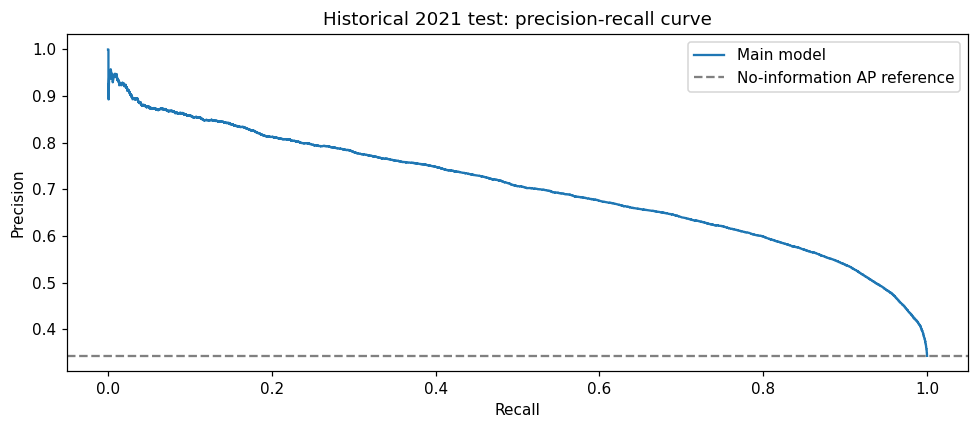

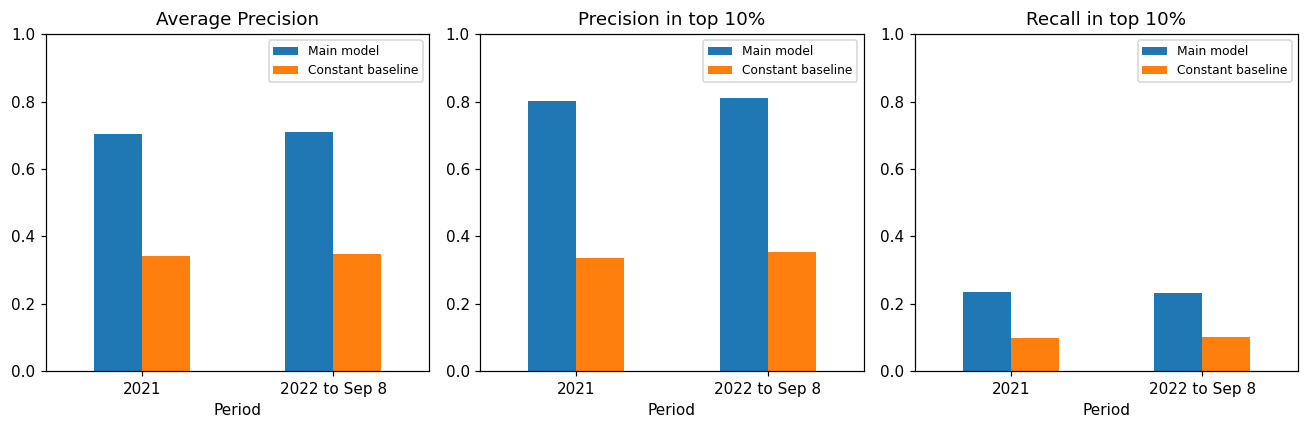

In [24]:
precision, recall, _ = precision_recall_curve(y["test"], predictions["test"]["hgb_full"])
plt.plot(recall, precision, label="Main model")
plt.axhline(y["test"].mean(), color="gray", linestyle="--", label="No-information AP reference")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Historical 2021 test: precision-recall curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "03_precision_recall.png")
plt.show()

held = scores[scores.split.isin(["test", "stress"])].copy()
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, metric, title in zip(axes, ["ap", "precision10", "recall10"],
                           ["Average Precision", "Precision in top 10%", "Recall in top 10%"]):
    plotted = held.pivot(index="split", columns="name", values=metric).reindex(["test", "stress"])
    plotted = plotted.rename(index={"test": "2021", "stress": "2022 to Sep 8"},
                             columns={"hgb_full": "Main model", "prior": "Constant baseline"})
    plotted.plot.bar(ax=ax)
    ax.set(title=title, ylim=(0, 1), xlabel="Period")
    ax.legend(title=None, fontsize=8)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / "04_temporal_performance.png")
plt.show()


### 4.3 Descriptive performance in weather category groups

The frozen model is evaluated in retained, known-grouped, unseen and missing
weather groups by year. Metrics require at least 100 events and both target
classes; otherwise they are left missing and the reason is recorded.
Top 10% here is selected within each subgroup, not the global alert list.
These diagnostics do not select a new vocabulary or a new model.

In [25]:
subgroup_rows = []
for split in ["validation", "test", "stress"]:
    years = cleaned_raw[split]["_t"].dt.year
    for column in WCAT:
        status = category_status(before_categories[split][column], column)
        for year in years.unique():
            for group in ["retained", "known_grouped", "unseen", "missing"]:
                mask = (years.eq(year) & status.eq(group)).to_numpy()
                count = int(mask.sum())
                row = {"split": split, "year": int(year), "column": column,
                       "status": group, "events": count,
                       "positive_rate": float(y[split][mask].mean()) if count else np.nan}
                if count >= 100 and len(np.unique(y[split][mask])) == 2:
                    row.update(evaluate(y[split][mask], predictions[split]["hgb_full"][mask], ties[split][mask]))
                    row["metric_status"] = "computed within subgroup"
                else:
                    row["metric_status"] = "too small or only one class"
                subgroup_rows.append(row)
subgroup_scores = pd.DataFrame(subgroup_rows)
subgroup_scores.to_csv(REPORTS / "weather_subgroup_scores.csv", index=False)
display(subgroup_scores[subgroup_scores.column.eq("Weather_Condition")].round(4))


,split,year,column,status,events,positive_rate,...,ap,auc,recall10,precision10,selected_count,metric_status
4,validation,2020,Weather_Condition,retained,23952,0.3011,...,0.7012,0.8525,0.2679,0.8063,2396.0,computed within subgroup
5,validation,2020,Weather_Condition,known_grouped,1126,0.3881,...,0.7474,0.8359,0.2174,0.8407,113.0,computed within subgroup
6,validation,2020,Weather_Condition,unseen,6,0.3333,...,NaN,NaN,NaN,NaN,NaN,too small or only one class
7,validation,2020,Weather_Condition,missing,24916,0.3000,...,0.6929,0.8483,0.2634,0.7901,2492.0,computed within subgroup
12,test,2021,Weather_Condition,retained,47777,0.3400,...,0.7160,0.8427,0.2416,0.8215,4778.0,computed within subgroup
13,test,2021,Weather_Condition,known_grouped,1954,0.4386,...,0.7407,0.8158,0.1832,0.8010,196.0,computed within subgroup
14,test,2021,Weather_Condition,unseen,12,0.4167,...,NaN,NaN,NaN,NaN,NaN,too small or only one class
15,test,2021,Weather_Condition,missing,50256,0.3416,...,0.6937,0.8320,0.2308,0.7881,5026.0,computed within subgroup
20,stress,2022,Weather_Condition,retained,23915,0.3426,...,0.7191,0.8398,0.2414,0.8269,2392.0,computed within subgroup
21,stress,2022,Weather_Condition,known_grouped,1081,0.4191,...,0.7545,0.8221,0.2119,0.8807,109.0,computed within subgroup


### 4.4 Automated consistency checks against repository artifacts

Check targets, temporal boundaries, feature lists, transformation ledgers and
metrics. Compare reproduced scores with historical tables, and verify that
their rounded main results appear in README and the report. These checks
establish internal consistency, not independent confirmation of the dataset's
labels, source documentation or absence of every possible leakage path.

Physical-bound corrections, if any, must be disclosed as a changed preparation
policy; they prevent presenting the run as an exact historical reproduction.

In [26]:
checks = []
def check(name, condition):
    checks.append({"check": name, "passed": bool(condition)})
    assert condition, name

check("33 admissible inputs", len(builder.columns) == 33 and not set(builder.columns) & FORBIDDEN)
check("no essential records removed in this reproduction", quality.invalid_date_or_label.sum() == 0)
check("no physical-bound corrections in these samples", invalid_values.invalid_values.sum() == 0)
check("full CSV row count matches documentation", audit["rows"] == 7728394 and audit["columns"] == 46)
historical_audit = json.loads((ROOT / "results/audit/audit.json").read_text(encoding="utf-8"))
check("sample sizes and prevalences match audit", audit["samples"] == historical_audit["samples"])
check("weather reasons partition each sample", weather_audit.events.eq(
    weather_audit.eligible_weather + weather_audit.future_observation +
    weather_audit.older_than_120_minutes + weather_audit.missing_or_invalid_timestamp).all())
mapping_counts = mappings.groupby(["split", "column", "rule"])["count"].sum()
summary_counts = changes.set_index(["split", "column", "rule"]).changed_cells
check("every changed value has a counted before/after mapping",
      summary_counts.eq(mapping_counts.reindex(summary_counts.index, fill_value=0)).all())
grouped_frequency = frequencies.groupby(["split", "column", "rule", "stage"])["count"].sum()
check("frequency denominators match samples", all(count == len(cleaned_raw[key[0]])
      for key, count in grouped_frequency.items()))
direction_fixture = cleaned_raw["train"].iloc[:2].copy()
direction_fixture["Wind_Direction"] = ["NE", "NW"]
direction_fixture["Weather_Timestamp"] = direction_fixture["_t"].astype(str)
check("directions NE and NW remain distinct",
      raw_features(direction_fixture)[0].Wind_Direction.tolist() == ["NE", "NW"])
historical_builder = FeatureBuilder().fit(raw["train"])
for split in X:
    pd.testing.assert_frame_equal(X[split], historical_builder.transform(raw[split]))
check("prepared inputs reproduce historical builder exactly", True)
historical = pd.concat([pd.read_csv(ROOT / "results/validation_models.csv").assign(split="validation"),
                        pd.read_csv(ROOT / "results/heldout_models.csv")], ignore_index=True)
comparison = scores.merge(historical[["split", "name", "n", "prevalence", "ap", "auc", "recall10", "precision10"]],
                          on=["split", "name"], suffixes=("_new", "_historical"), validate="one_to_one")
check("all baseline and model rows matched", len(comparison) == 6)
for metric in ["n", "prevalence", "ap", "auc", "recall10", "precision10"]:
    delta = comparison[f"{metric}_new"] - comparison[f"{metric}_historical"]
    comparison[f"{metric}_difference"] = delta
    check(f"historical {metric} reproduced", np.allclose(delta, 0, rtol=0, atol=1e-9))
for split in ["validation", "test", "stress"]:
    baseline = scores[(scores.split == split) & (scores.name == "prior")].iloc[0]
    check(f"{split} baseline AP equals prevalence", np.isclose(baseline.ap, baseline.prevalence))
    check(f"{split} baseline AUC equals 0.5", np.isclose(baseline.auc, 0.5))
readme = (ROOT / "README.md").read_text(encoding="utf-8")
report = (ROOT / "docs/RAPPORT.md").read_text(encoding="utf-8")
for split in ["test", "stress"]:
    value = scores[(scores.split == split) & scores.name.eq("hgb_full")].iloc[0].ap
    token = f"{value:.4f}"
    check(f"{split} AP agrees with README", token in readme or token.replace(".", ",") in readme)
    check(f"{split} AP agrees with report", token in report or token.replace(".", ",") in report)
comparison.to_csv(REPORTS / "historical_comparison.csv", index=False)
check_table = pd.DataFrame(checks)
check_table.to_csv(REPORTS / "consistency_checks.csv", index=False)
(REPORTS / "run_metadata.json").write_text(json.dumps({"versions": versions,
    "csv_signature": signature, "settings": settings, "training_seconds": training_seconds,
    "baseline_prior": prior, "passed_checks": len(checks)}, indent=2), encoding="utf-8")
display(check_table)
display(comparison[["split", "name", "ap_new", "ap_historical", "ap_difference"]])


,check,passed
0,33 admissible inputs,True
1,no essential records removed in this reproduction,True
2,no physical-bound corrections in these samples,True
3,full CSV row count matches documentation,True
4,sample sizes and prevalences match audit,True
5,weather reasons partition each sample,True
6,every changed value has a counted before/after...,True
7,frequency denominators match samples,True
8,directions NE and NW remain distinct,True
9,prepared inputs reproduce historical builder e...,True


,split,name,ap_new,ap_historical,ap_difference
0,validation,prior,0.302520,0.302520,0.000000e+00
1,validation,hgb_full,0.696948,0.696948,1.110223e-16
2,test,prior,0.342733,0.342733,5.551115e-17
3,test,hgb_full,0.703118,0.703118,0.000000e+00
4,stress,prior,0.346960,0.346960,0.000000e+00
5,stress,hgb_full,0.709157,0.709157,1.110223e-16


## 5. Conclusion

The following conclusion is generated from the scores computed in this run.
It separates ranking quality, alert-budget coverage and deployment limitations.


In [27]:
test_main = scores[scores.split.eq("test") & scores.name.eq("hgb_full")].iloc[0]
test_prior = scores[scores.split.eq("test") & scores.name.eq("prior")].iloc[0]
stress_main = scores[scores.split.eq("stress") & scores.name.eq("hgb_full")].iloc[0]
display(Markdown(f"""
On the historical 2021 test, the main model obtains **AP {test_main.ap:.4f}**
and **ROC-AUC {test_main.auc:.4f}**, compared with baseline AP {test_prior.ap:.4f}.
Among the highest-ranked 10% of incidents, **{100 * test_main.precision10:.2f}%**
are positive and **{100 * test_main.recall10:.2f}%** of all positives are found.
AP is **{stress_main.ap:.4f}** on the available 2022 period.

This reproduces the repository's main ranking results with one trained model
and one inexpensive baseline. It does not demonstrate that all 33 inputs are
necessary, or that this algorithm is better than every alternative.
"""))



On the historical 2021 test, the main model obtains **AP 0.7031**
and **ROC-AUC 0.8362**, compared with baseline AP 0.3427.
Among the highest-ranked 10% of incidents, **80.13%**
are positive and **23.38%** of all positives are found.
AP is **0.7092** on the available 2022 period.

This reproduces the repository's main ranking results with one trained model
and one inexpensive baseline. It does not demonstrate that all 33 inputs are
necessary, or that this algorithm is better than every alternative.


### Limits and possible next work

- Results concern recorded accidents from one provider, not accident occurrence risk.
- Most positive events are Severity 3; binary metrics alone do not validate
  detection of the rare Severity 4 class.
- Actual feature publication and label assignment times are unknown.
- The notebook compares raw, Platt-scaled and isotonic probabilities using a
  historical temporal split. This does not validate deployment calibration;
  threshold policies remain illustrative and depend on the cost of misses,
  false alarms and available review capacity.
- Category grouping can lose distinctions; drift reports describe this risk
  without proving a causal effect. Caps 10/15/25 were not compared in this notebook.
- 2021 and 2022 have already been consulted. A changed model would need a genuinely
  later independent period for a new confirmation.
- No uncertainty intervals or exhaustive algorithm search are claimed here.

With more time, validate threshold stability on additional future periods, compare
operational costs, evaluate new providers and investigate validation-only
alternatives for category grouping.

### Deliverable checklist

Add all group member names. Keep the notebook below 10 MB. Submit the notebook,
`traffic_impact/` modules and requirements, with the repository structure preserved.
Do not submit the CSV, runtime dependencies or caches. Full audit tables and
figures generated here are under `data/main_notebook/reports/` and `figures/`;
copy selected small tables to a submission folder if desired.